In [1]:
from astropy import units
from astropy.time import Time

from matplotlib import pyplot

from src.selflensing.fitting import self_lensing_system_from_fit
from src.selflensing.generators import LightcurveGenerator, RVGenerator
from src.selflensing.models import SelfLensingSystem

In [ ]:
sls = SelfLensingSystem(
    a=5 * units.AU,
    b=0 * units.dimensionless_unscaled,
    Macc=9*units.M_sun,
    Mcomp=1*units.M_sun,
    Rcomp=10*units.R_sun,
    e=0 * units.dimensionless_unscaled,
)
sls.porb

<Quantity 326.69570161 d>

In [3]:
start_time = Time("2025-01-01")
end_time = Time("2026-01-01")
peak_time = Time("2025-06-01")

In [4]:
lcg = LightcurveGenerator(sls, start_time=start_time, end_time=end_time, peak_time=peak_time, ev=True, db=True, sl=True, lensing_method='Heyrovsky')
rvg = RVGenerator(sls, start_time=start_time, end_time=end_time, peak_time=peak_time)

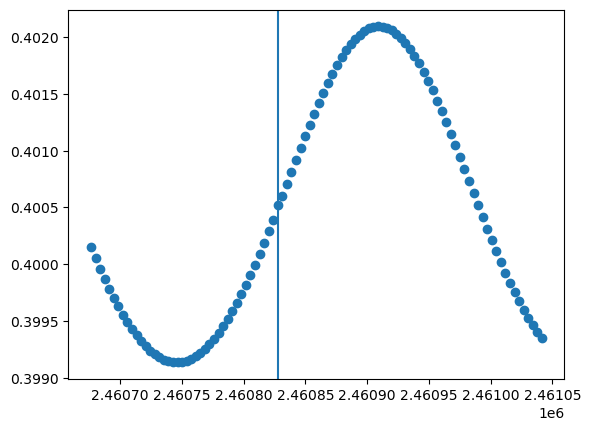

In [5]:
pyplot.scatter(lcg.times.jd, lcg.flux_array)
pyplot.axvline(peak_time.jd)

In [ ]:
sls_fit, sampler = self_lensing_system_from_fit(
    rv_times=rvg.times,
    observed_rv=rvg.rv,
    observed_rv_err=1 * rvg.units,
    lc_times=lcg.times,
    observed_lc=lcg.flux_array,
    observed_lc_err=1 * lcg.units,
    peak_time=peak_time,
    Mcomp=sls.Mcomp,
    Rcomp=sls.Rcomp,
    Teff=sls.Teff,
    nsteps=500,
    nwalkers=20,
    burn=10,
)
lcg_fit = LightcurveGenerator(sls_fit, start_time=start_time, end_time=end_time, peak_time=peak_time)
rvg_fit = RVGenerator(sls_fit, start_time=start_time, end_time=end_time, peak_time=peak_time)

  0%|          | 0/500 [00:00<?, ?it/s]/opt/anaconda3/envs/slpkg/lib/python3.13/site-packages/emcee/moves/red_blue.py:99: RuntimeWarning: invalid value encountered in scalar subtract
  lnpdiff = f + nlp - state.log_prob[j]
 27%|██▋       | 134/500 [00:16<00:45,  8.12it/s]

In [ ]:
sls.a, sls.Macc, sls.b, sls.e, sls.periapsis_phase, sls.porb

(<Quantity 2. AU>,
 <Quantity 9. solMass>,
 <Quantity 0.>,
 <Quantity 0.>,
 <Quantity 0. rad>,
 <Quantity 326.69570161 d>)

In [ ]:
sls_fit.a, sls_fit.Macc, sls_fit.b, sls_fit.e, sls_fit.periapsis_phase, sls_fit.porb

(<Quantity 2.00612453 AU>,
 <Quantity 9.25310606 solMass>,
 <Quantity 0.>,
 <Quantity 0.05648963>,
 <Quantity 1.45814882 rad>,
 <Quantity 324.12127233 d>)

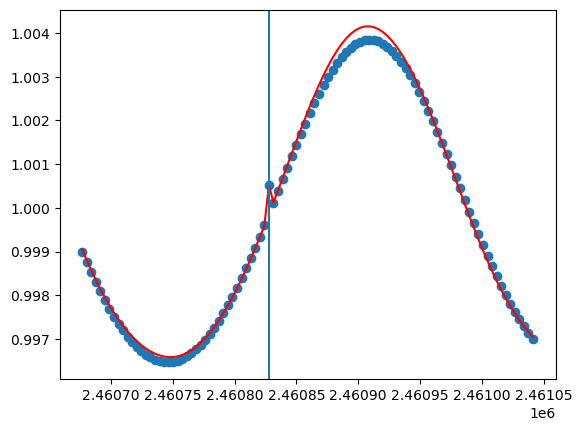

In [ ]:
pyplot.scatter(lcg.times.jd, lcg.flux_array)
pyplot.plot(lcg_fit.times.jd, lcg_fit.flux_array, c='red')
pyplot.axvline(peak_time.jd)

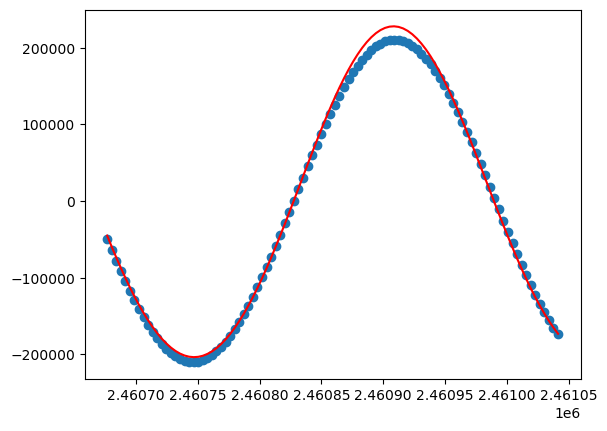

In [ ]:
pyplot.scatter(rvg.times.jd, rvg.rv)
pyplot.plot(rvg_fit.times.jd, rvg_fit.rv, c='red')

Text(0.5, 0, 'step number')

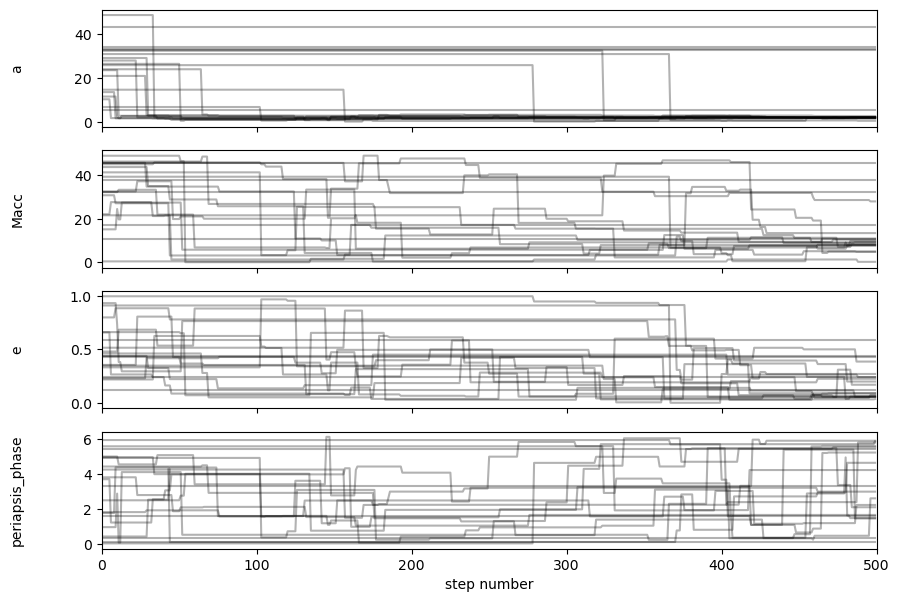

In [ ]:
from matplotlib import pyplot as plt
labels = ["a", "Macc", 'e', 'periapsis_phase']
fig, axes = plt.subplots(len(labels), figsize=(10, 7), sharex=True)
samples = sampler.get_chain()#discard=100)
flat_samples = sampler.get_chain(flat=True)
for i in range(len(labels)):
    ax = axes[i]
    ax.plot(samples[:, :, i], "k", alpha=0.3)
    ax.set_xlim(0, len(samples))
    ax.set_ylabel(labels[i])
    ax.yaxis.set_label_coords(-0.1, 0.5)

axes[-1].set_xlabel("step number")

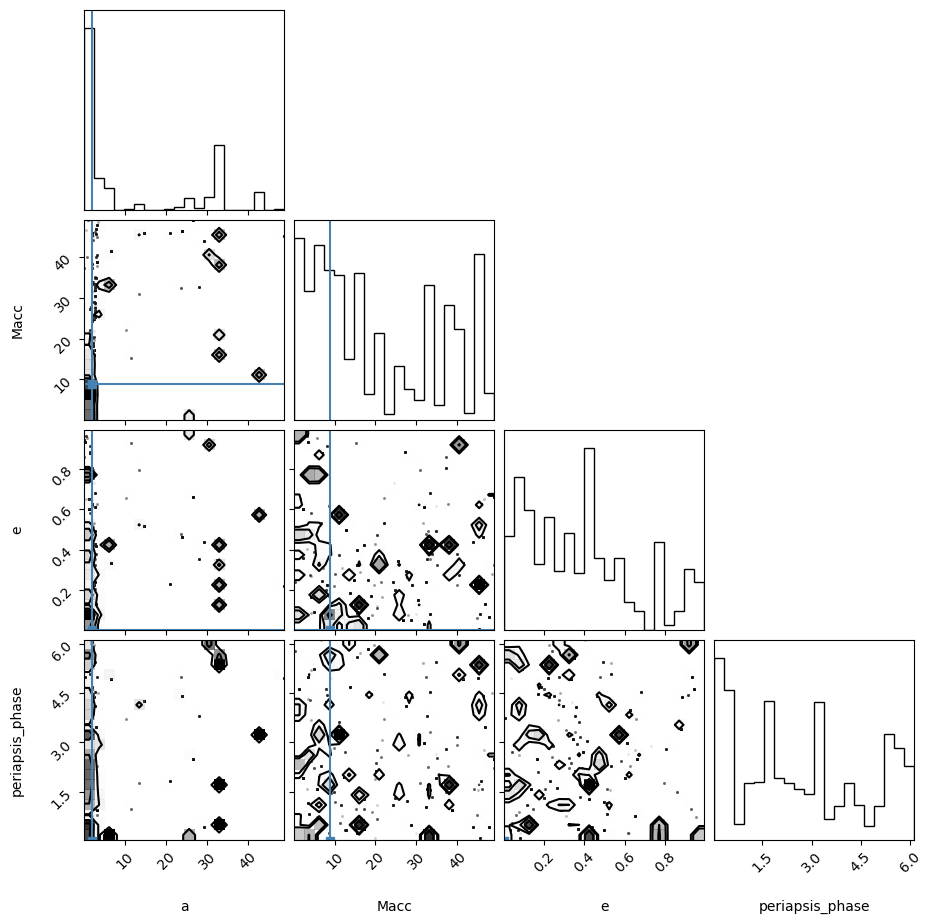

In [ ]:
import corner

fig = corner.corner(
    flat_samples, labels=labels, truths=[sls.a.value, sls.Macc.value, sls.e.value, sls.periapsis_phase.value]
)